# 00. Research question and scope

This notebook states the research question and sets out why the project uses the retailer's behaviour log, why it studies TVs and why Samsung is the benchmark for LG. It reads the two original course files. The scope was chosen after exploring the data, and the tables and figures below are the evidence behind that choice.

## 1. Research question

**Primary question.** How much of LG's shortfall in TV purchases against Samsung at this retailer is associated with fewer sessions reaching LG's models, with the number of models considered per reaching session, and with lower purchase conversion?

**Supporting question.** For the conversion part, how does the comparison between LG and Samsung change once the shopper's browsing before the model is opened, the price and the week are taken into account?

The decision maker is LG's team responsible for this retailer. The analysis describes where the shortfall arises and does not estimate the effect of any action.

In [1]:
from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter
from IPython.display import display, Image, Markdown

DATA_DIR = Path('..') / 'data' / '01_LG_Electronics_Appliances'
OUT = Path('results') / 'scope'
for sub in ['tables', 'figures']:
    (OUT / sub).mkdir(parents=True, exist_ok=True)
    for old in (OUT / sub).glob('*'):
        old.unlink()
F_BEH, F_REV = 'electronics_market_behavior.csv', 'appliance_brand_reviews.csv'
KEY = ['user_id', 'session_id', 'product_id']
SESSION = ['user_id', 'session_id']
CATEGORIES = {'tv': 'TV', 'washing_machine': 'Washing machine', 'refrigerator': 'Refrigerator',
              'vacuum_cleaner': 'Vacuum cleaner', 'microwave': 'Microwave', 'monitor': 'Monitor'}
COLORS = {'lg': '#A50034', 'samsung': '#1428A0'}
BRAND_NAMES = {'lg': 'LG', 'tcl': 'TCL', 'hp': 'HP', 'aoc': 'AOC', 'arg': 'ARG'}
GREY = '#8A8D91'
EXHIBITS = []

plt.rcParams.update({
    'font.size': 9, 'axes.titlesize': 9.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 9, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': '#e4e4e4', 'grid.linewidth': 0.6, 'axes.axisbelow': True, 'legend.frameon': False,
    'legend.fontsize': 8.5, 'savefig.dpi': 200})
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 90)
pct = FuncFormatter(lambda v, _: f'{v:g}%')

def save_table(tid, title, df, note, src):
    df = df.round(2)
    path = OUT / 'tables' / f"T{tid.replace('.', '_')}.csv"
    df.to_csv(path)
    EXHIBITS.append({'Exhibit': f'Table {tid}', 'Title': title, 'Note': note, 'File': f'tables/{path.name}',
                     'Built from': ', '.join(src)})
    display(Markdown(f'**Table {tid}. {title}**'))
    display(df)
    display(Markdown(f'*Note.* {note} Built from {", ".join(src)}.'))


def save_figure(fig, fid, title, note, src):
    full = f'{note} Built from {", ".join(src)}.'.strip()
    w, _ = fig.get_size_inches()
    fig.suptitle(f'Figure {fid}. {title}', x=0.01, ha='left', fontsize=10.5, fontweight='bold')
    fig.text(0.01, -0.015, '\n'.join(textwrap.wrap('Note. ' + full, width=int(w * 17))), fontsize=7.2,
             color='#555555', ha='left', va='top')
    path = OUT / 'figures' / f"F{fid.replace('.', '_')}.png"
    fig.savefig(path, bbox_inches='tight', facecolor='white')
    plt.close(fig)
    EXHIBITS.append({'Exhibit': f'Figure {fid}', 'Title': title, 'Note': full, 'File': f'figures/{path.name}',
                     'Built from': ', '.join(src)})
    display(Image(filename=str(path), width=820))


def mean_ci(y, *clusters):
    """Mean of y in % with a 95% interval, standard error clustered on one or two dimensions."""
    y = np.asarray(y, float)
    e, n = y - y.mean(), len(y)

    def v(groups):
        s = pd.Series(e).groupby(np.asarray(groups)).sum()
        return 0.0 if len(s) < 2 else len(s) / (len(s) - 1) * (s ** 2).sum() / n ** 2

    if len(clusters) == 1:
        var = v(clusters[0])
    else:
        a, b = np.asarray(clusters[0]), np.asarray(clusters[1])
        var = v(a) + v(b) - v(pd.Series(a).astype(str) + '|' + pd.Series(b).astype(str))
        var = max(var, v(a), v(b)) if var <= 0 else var
    se = np.sqrt(var)
    return 100 * y.mean(), 100 * (y.mean() - 1.96 * se), 100 * (y.mean() + 1.96 * se)


def gap_se(d):
    """LG minus Samsung conversion (pp) and its standard errors: two-way by user and model, by model only, and with
    considerations treated as independent."""
    d = d[d['brand'].isin(['lg', 'samsung'])].assign(lg=lambda x: (x['brand'] == 'lg').astype(int))
    m = smf.ols('purchased ~ lg', d)
    se = {'independent': m.fit().bse['lg'],
          'product': m.fit(cov_type='cluster', cov_kwds={'groups': pd.factorize(d['product_id'])[0]}).bse['lg'],
          'user_product': m.fit(cov_type='cluster', cov_kwds={'groups': np.column_stack(
              [pd.factorize(d['user_id'])[0], pd.factorize(d['product_id'])[0]])}).bse['lg']}
    gap = d.loc[d['lg'] == 1, 'purchased'].mean() - d.loc[d['lg'] == 0, 'purchased'].mean()
    return 100 * gap, {k: 100 * v for k, v in se.items()}

## 2. The two course files

The behaviour log records one event per row, either a view, a cart addition or a purchase, with the user, session, product, brand, category, time and price. It shows how shoppers considered and bought products at one retailer. It has no product specifications, stock levels, traffic sources, advertising, costs or assigned interventions. The course kept LG and five competitors in each product category and sampled whole sessions, so the file contains neither complete user histories nor market shares. Table 0.1 audits the file before anything is built from it.

In [2]:
behavior = pd.read_csv(DATA_DIR / F_BEH)
reviews = pd.read_csv(DATA_DIR / F_REV)

ev = behavior.drop_duplicates().copy()
ev['event_time'] = pd.to_datetime(ev['event_time'], utc=True, errors='coerce')
for col in ['event_type', 'brand', 'product_category']:
    ev[col] = ev[col].str.strip().str.lower()
invalid = ev.isna().any(axis=1) | ~(ev['price'] > 0) | ~ev['event_type'].isin(['view', 'cart', 'purchase'])
assert not invalid.any()
mixed = (ev.groupby('product_id')[['brand', 'product_category']].nunique() > 1).any(axis=1)
t01 = pd.Series({
    'Events in the file': f'{len(behavior):,}',
    'Exact duplicate events, identical on all eight columns': f'{len(behavior) - len(ev):,}',
    'Events after removing the duplicates': f'{len(ev):,}',
    'Events with a missing value, a price of zero or less, or an unknown event type': f'{int(invalid.sum()):,}',
    'Products recorded under more than one brand or category': f'{int(mixed.sum()):,}',
    'Session IDs that appear under more than one user': f"{int((ev.groupby('session_id')['user_id'].nunique() > 1).sum()):,}",
    'Users': f"{ev['user_id'].nunique():,}",
    'Sessions (user and session ID together)': f'{ev[SESSION].drop_duplicates().shape[0]:,}',
    'Products': f"{ev['product_id'].nunique():,}",
    'Brands': f"{ev['brand'].nunique():,}",
    'Product categories': f"{ev['product_category'].nunique():,}",
    'First event (UTC)': f"{ev['event_time'].min():%d %B %Y, %H:%M}",
    'Last event (UTC)': f"{ev['event_time'].max():%d %B %Y, %H:%M}",
}, name='Value').to_frame()
t01.index.name = 'Check'
save_table('0.1', 'The behaviour file', t01,
           'Event type, brand and category are compared after removing spaces and capitals. Every count after the third row '
           'refers to the events left after removing the duplicates.', [F_BEH])

**Table 0.1. The behaviour file**

,Value
Check,
Events in the file,"649,605"
"Exact duplicate events, identical on all eight columns","1,247"
Events after removing the duplicates,"648,358"
"Events with a missing value, a price of zero or less, or an unknown event type",0
Products recorded under more than one brand or category,0
Session IDs that appear under more than one user,4
Users,"138,863"
Sessions (user and session ID together),"162,706"
Products,"1,613"


*Note.* Event type, brand and category are compared after removing spaces and capitals. Every count after the third row refers to the events left after removing the duplicates. Built from electronics_market_behavior.csv.

The reviews file holds star ratings and text for appliances, with the review date, a verified-purchase flag and the listed price of the product. Table 0.2 checks whether the two files can be linked, and Table 0.3 describes the reviews of LG and Samsung products.

In [3]:
reviews['brand_lc'] = reviews['brand'].str.strip().str.lower()
reviews['review_date'] = pd.to_datetime(reviews['review_date'])
t02 = pd.Series({
    'Product categories in the behaviour file': ', '.join(sorted(ev['product_category'].unique())),
    'Product categories in the reviews file': ', '.join(sorted(reviews['product_category'].unique())),
    'Reviews of TVs': f"{int(reviews['product_category'].str.contains('tv', case=False).sum()):,}",
    'Product IDs that appear in both files': f"{len(set(ev['product_id']) & set(reviews['product_id'])):,}",
    'User identifier in the reviews file': 'yes' if 'user_id' in reviews.columns else 'no',
}, name='Value').to_frame()
t02.index.name = 'Check'
save_table('0.2', 'Overlap between the two course files', t02, 'Categories are listed as they are coded in each file.',
           [F_BEH, F_REV])

main = reviews[reviews['brand_lc'].isin(['lg', 'samsung'])]
t03 = main.groupby(['product_category', 'brand']).agg(
    Reviews=('review_id', 'size'), Products=('product_id', 'nunique'), mean_rating=('review_rating', 'mean'),
    verified=('verified_purchase', 'mean'), price_missing=('price', lambda s: s.isna().mean()),
    first=('review_date', 'min'), last=('review_date', 'max'))
t03['verified'] *= 100
t03['price_missing'] *= 100
t03['first'] = t03['first'].dt.strftime('%Y-%m')
t03['last'] = t03['last'].dt.strftime('%Y-%m')
t03.columns = ['Reviews', 'Products', 'Mean rating (1 to 5)', 'Verified purchases (%)', 'Listed price missing (%)',
               'First review', 'Last review']
t03.index.names = ['Review category', 'Brand']
save_table('0.3', 'Reviews of LG and Samsung appliances by category', t03,
           f"The file holds {len(reviews):,} reviews of {reviews['brand'].nunique()} brands, dated from "
           f"{reviews['review_date'].min():%B %Y} to {reviews['review_date'].max():%B %Y}.", [F_REV])

**Table 0.2. Overlap between the two course files**

,Value
Check,
Product categories in the behaviour file,"microwave, monitor, refrigerator, tv, vacuum_cleaner, washing_machine"
Product categories in the reviews file,"air_conditioner, cooking, dishwasher, laundry, other_appliance, refrigerator_freezer"
Reviews of TVs,0
Product IDs that appear in both files,0
User identifier in the reviews file,no


*Note.* Categories are listed as they are coded in each file. Built from electronics_market_behavior.csv, appliance_brand_reviews.csv.

**Table 0.3. Reviews of LG and Samsung appliances by category**

Reviews  Products  Mean rating (1 to 5)  Verified purchases (%)  Listed price missing (%) First review Last review
Review category      Brand                                                                                                                      
cooking              LG           327        57                  3.31                   54.13                     94.19      2006-12     2023-05
                     Samsung      568        81                  2.46                   23.77                     97.18      2009-09     2023-07
dishwasher           LG            88        13                  1.64                    1.14                    100.00      2006-07     2023-07
                     Samsung      210        26                  1.50                    4.76                     99.52      2010-07     2023-07
laundry              LG          1287       186                  2.91                   27.89                     98.06      2006-11     2023-08
                     Samsung      613       138                  2.07                   16.15                     93.96      2009-08     2023-07
other_appliance      Samsung        6         2                  2.33                   66.67                     16.67      2022-04     2023-05
refrigerator_freezer LG          1221       165                  2.84                   39.72                     72.81      2008-03     2023-07
                     Samsung     1287       166                  2.14                   12.90                     97.67      2008-08     2023-06

*Note.* The file holds 20,004 reviews of 8 brands, dated from July 2004 to September 2023. Built from appliance_brand_reviews.csv.

The two files share no product IDs, the reviews file has no user identifier, and the reviews contain no TVs, so a review cannot be attached to a TV consideration or linked to a shopper in the behaviour log. The reviews would support a separate study of satisfaction in the categories where both brands have reviews, which would answer a different managerial question. The project therefore uses the behaviour log only.

## 3. Why TVs

Table 0.4 compares the six product categories of the behaviour log. Considerations are built for every category with the rule that `01_build_tv_dataset.py` applies to TVs, described in `tv_considerations_dictionary.md`. The top-five share is the percentage of a brand's considerations in the category that go to its five most-considered models, a simple measure of how concentrated its traffic is. Figure 0.1 places each category by the conversion gap between LG and Samsung and by how often shoppers who opened both brands opened Samsung first. Intervals in this notebook use standard errors clustered by user and by product.

**Table 0.4. LG and Samsung in the six product categories**

,Events,Users,Brands,LG considerations,Samsung considerations,LG purchased considerations,Samsung purchased considerations,LG models,Samsung models,LG top-five share (%),Samsung top-five share (%)
Category,,,,,,,,,,,
TV,211958,50373,6,22213,52499,505,1645,105,91,42.31,52.38
Washing machine,161871,35711,6,21959,32684,544,910,69,48,51.16,58.40
Vacuum cleaner,117983,27551,6,5493,26308,132,906,27,73,60.00,50.44
Refrigerator,108259,26554,6,13079,9950,191,132,49,41,59.77,49.88
Microwave,26569,8716,6,2822,4701,71,150,17,29,89.40,62.69
Monitor,21718,4778,6,1312,3718,13,59,40,61,31.86,48.52


*Note.* Categories are ordered by LG and Samsung considerations together. Events and users cover all brands in the category. Models count the products with at least one view. Built from electronics_market_behavior.csv.

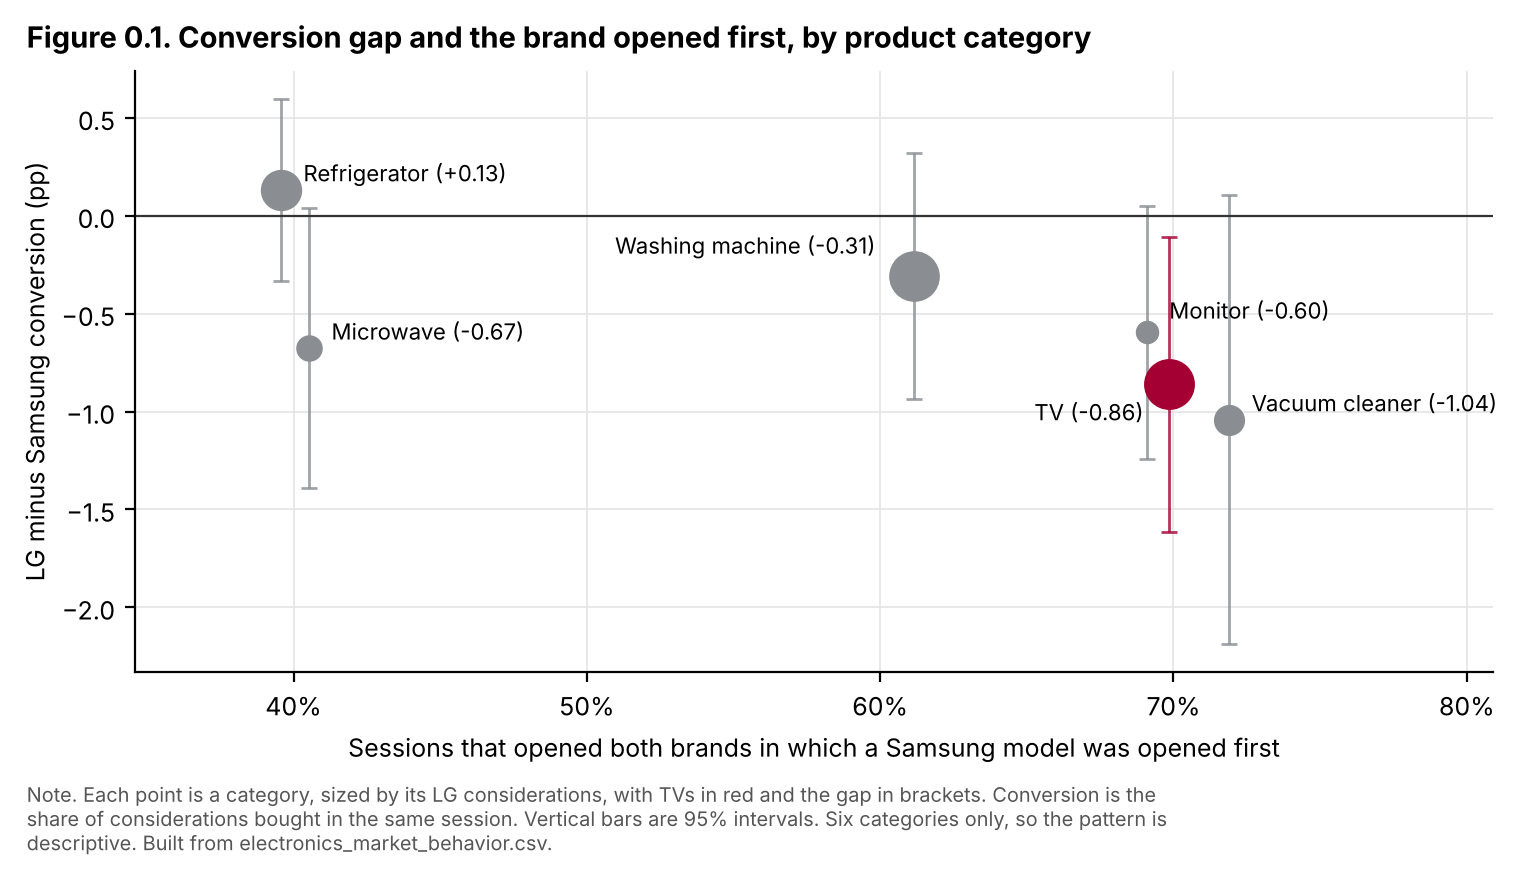

In [4]:
views = ev[ev['event_type'] == 'view']
cons = (views.sort_values('event_time', kind='stable').drop_duplicates(KEY)
        [KEY + ['brand', 'product_category', 'event_time', 'price']].rename(columns={'event_time': 'first_view'}))
last_buy = ev[ev['event_type'] == 'purchase'].groupby(KEY)['event_time'].max().rename('last_purchase')
cons = cons.join(last_buy, on=KEY)
cons['purchased'] = (cons['last_purchase'] >= cons['first_view']).astype(int)


def top5(d):
    n = d.groupby('product_id').size().sort_values(ascending=False)
    return 100 * n.head(5).sum() / n.sum()


rows = []
for c, d in cons.groupby('product_category'):
    lg, sm = d[d['brand'] == 'lg'], d[d['brand'] == 'samsung']
    e = ev[ev['product_category'] == c]
    gap, se = gap_se(d)
    first = d[d['brand'].isin(['lg', 'samsung'])].groupby(SESSION + ['brand'])['first_view'].min().unstack().dropna()
    rows.append({'Category': CATEGORIES[c], 'Events': len(e), 'Users': e['user_id'].nunique(), 'Brands': e['brand'].nunique(),
                 'LG considerations': len(lg), 'Samsung considerations': len(sm),
                 'LG purchased considerations': int(lg['purchased'].sum()),
                 'Samsung purchased considerations': int(sm['purchased'].sum()),
                 'LG models': lg['product_id'].nunique(), 'Samsung models': sm['product_id'].nunique(),
                 'LG top-five share (%)': top5(lg), 'Samsung top-five share (%)': top5(sm),
                 'gap': gap, 'gap_lo': gap - 1.96 * se['user_product'], 'gap_hi': gap + 1.96 * se['user_product'],
                 'samsung_first': 100 * (first['samsung'] < first['lg']).mean()})
cat = pd.DataFrame(rows).set_index('Category')
cat = cat.loc[(cat['LG considerations'] + cat['Samsung considerations']).sort_values(ascending=False).index]
t04 = cat.drop(columns=['gap', 'gap_lo', 'gap_hi', 'samsung_first'])
save_table('0.4', 'LG and Samsung in the six product categories', t04,
           'Categories are ordered by LG and Samsung considerations together. Events and users cover all brands in the '
           'category. Models count the products with at least one view.', [F_BEH])

fig, ax = plt.subplots(figsize=(7.5, 3.8), layout='constrained')
size = 40 + 260 * cat['LG considerations'] / cat['LG considerations'].max()
OFFSETS = {'TV': (-9, -13), 'Monitor': (8, 5), 'Washing machine': (-14, 8)}
for name, r in cat.iterrows():
    col = COLORS['lg'] if name == 'TV' else GREY
    ax.errorbar(r['samsung_first'], r['gap'], yerr=[[r['gap'] - r['gap_lo']], [r['gap_hi'] - r['gap']]], fmt='none',
                ecolor=col, elinewidth=1, capsize=3, alpha=0.8)
    ax.scatter(r['samsung_first'], r['gap'], s=size[name], color=col, zorder=3)
    ax.annotate(f"{name} ({r['gap']:+.2f})", (r['samsung_first'], r['gap']), xytext=OFFSETS.get(name, (8, 3)),
                textcoords='offset points', fontsize=8, ha='right' if OFFSETS.get(name, (8, 3))[0] < 0 else 'left')
ax.axhline(0, color='#333333', lw=0.8)
ax.xaxis.set_major_formatter(pct)
ax.set_xlim(cat['samsung_first'].min() - 5, cat['samsung_first'].max() + 9)
ax.set_xlabel('Sessions that opened both brands in which a Samsung model was opened first')
ax.set_ylabel('LG minus Samsung conversion (pp)')
save_figure(fig, '0.1', 'Conversion gap and the brand opened first, by product category',
            'Each point is a category, sized by its LG considerations, with TVs in red and the gap in brackets. Conversion is '
            'the share of considerations bought in the same session. Vertical bars are 95% intervals. Six categories only, '
            'so the pattern is descriptive.', [F_BEH])

TVs have the largest combined LG and Samsung sample, both in considerations and in purchased considerations. Washing machines are the main alternative, since LG has slightly more purchased considerations there than in TVs, but their combined sample is smaller. Monitors have few LG purchases, and LG's microwave traffic is concentrated in five models. TVs were chosen because they combine the largest two-brand sample, a competitor priced like LG (Section 4) and a single kind of purchase decision.

Two other facts were checked and are not reasons for the choice. LG's refrigerators have a higher median price than its TVs (Table 0.5), so TVs are not LG's most expensive category, and the largest negative gap between LG and Samsung is in vacuum cleaners (Figure 0.1). The choice was made after looking at the data, so the comparison across categories documents it and cannot confirm it independently.

## 4. Why Samsung

Figures 0.2 and 0.3 compare the six TV brands. Table 0.5 screens every competitor of LG in every category by the price at the first view. The distance is the gap between the competitor's median price and LG's, as a percentage of LG's. The central-range overlap is the length of the price interval that the two brands' 25th-to-75th percentile ranges share, in the retailer's currency, and it is zero when the ranges do not meet. The last column is the share of the brand's considerations priced inside LG's 5th-to-95th percentile range in the same category. Figure 0.4 shows the full TV price distributions.

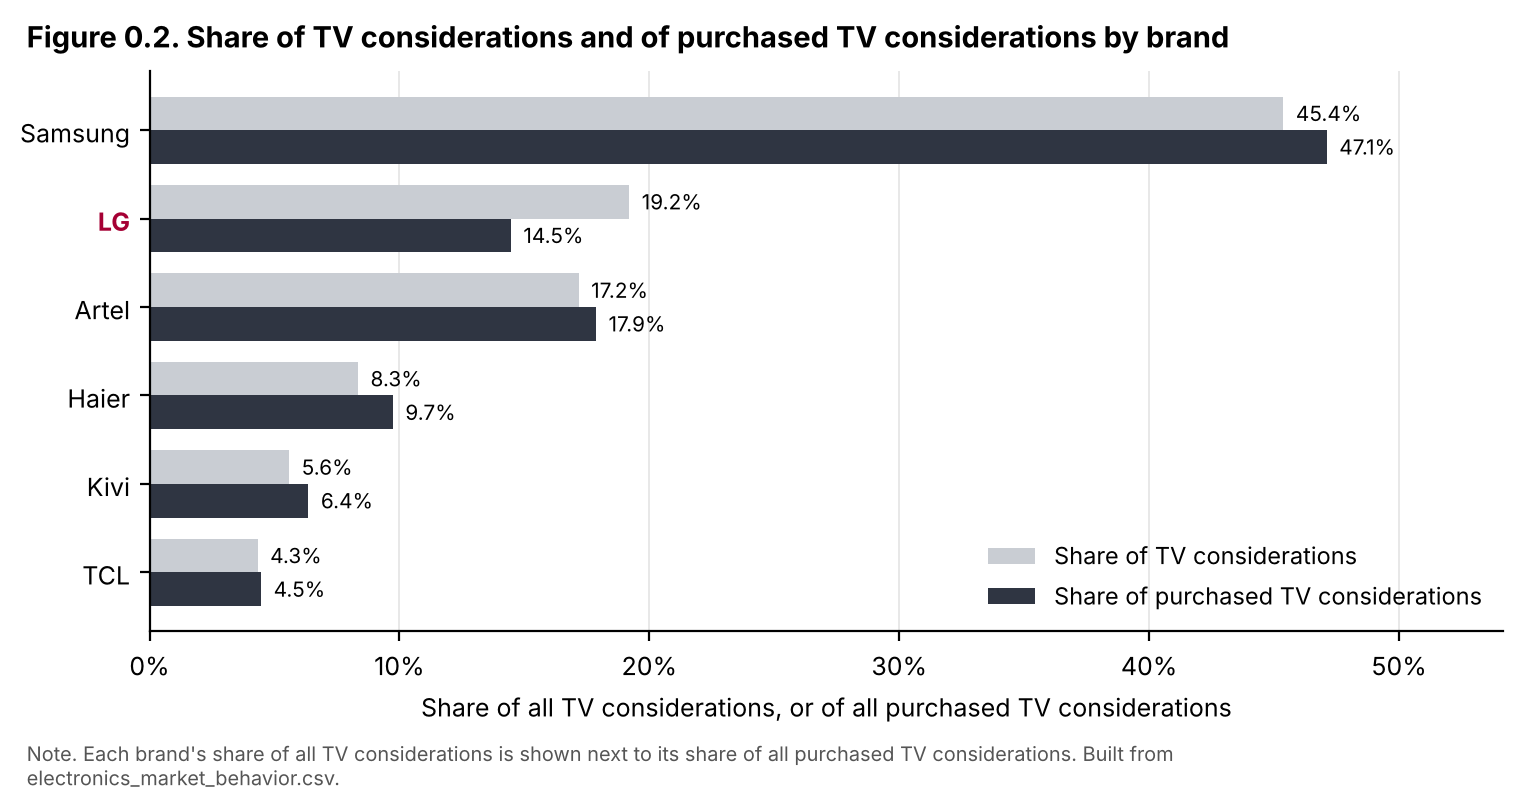

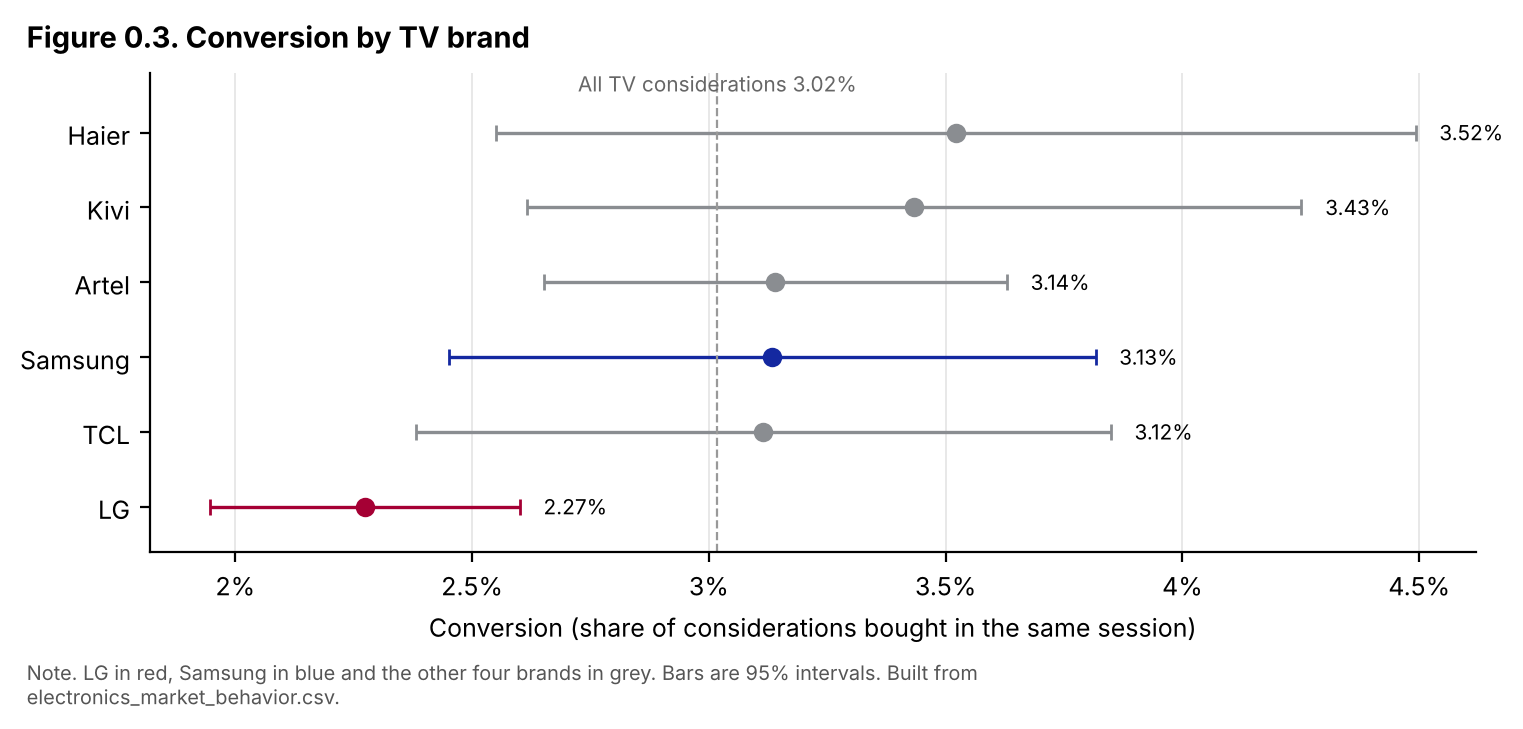

**Table 0.5. Price at the first view of each brand against LG, by product category**

Median price  Distance from LG's median (%)  Central-range overlap with LG  Considerations inside LG's 5th to 95th percentile range (%)
Category        Brand                                                                                                                                            
TV              LG              460.84                            NaN                            NaN                                                        90.37
                Samsung         493.96                           7.19                         244.39                                                        86.11
                TCL             251.95                          45.33                           0.00                                                        29.03
                Haier           231.64                          49.74                           0.00                                                        39.82
                Kivi            192.93                          58.14                           0.00                                                        34.68
                Artel           154.19                          66.54                           0.00                                                         9.20
Washing machine LG              380.96                            NaN                            NaN                                                        90.52
                Samsung         347.47                           8.79                          86.66                                                        85.81
                Beko            212.85                          44.13                           0.00                                                        10.37
                Indesit         194.90                          48.84                           0.00                                                         2.96
                Midea           120.72                          68.31                           0.00                                                         3.00
                Artel            93.75                          75.39                           0.00                                                         0.00
Vacuum cleaner  LG              172.38                            NaN                            NaN                                                        89.99
                Tefal           138.97                          19.38                          64.84                                                        72.30
                Bosch           115.81                          32.82                          80.28                                                        61.71
                Samsung          92.64                          46.26                          28.08                                                        45.76
                Vitek            77.17                          55.23                           4.60                                                        45.88
                Xiaomi          401.30                         132.80                           0.00                                                        12.81
Refrigerator    LG              535.12                            NaN                            NaN                                                        91.70
                Samsung         643.26                          20.21                         232.44                                                        98.75
                Indesit         302.43                          43.48                           0.00                                                         0.51
                Atlant          257.38                          51.90                           0.00                                                         2.61
                Beko            243.35                          54.52                           0.00                                      

*Note.* Prices are in the retailer's unidentified currency and weight each consideration equally. Within each category LG comes first, followed by its competitors from the closest median price to the farthest. Built from electronics_market_behavior.csv.

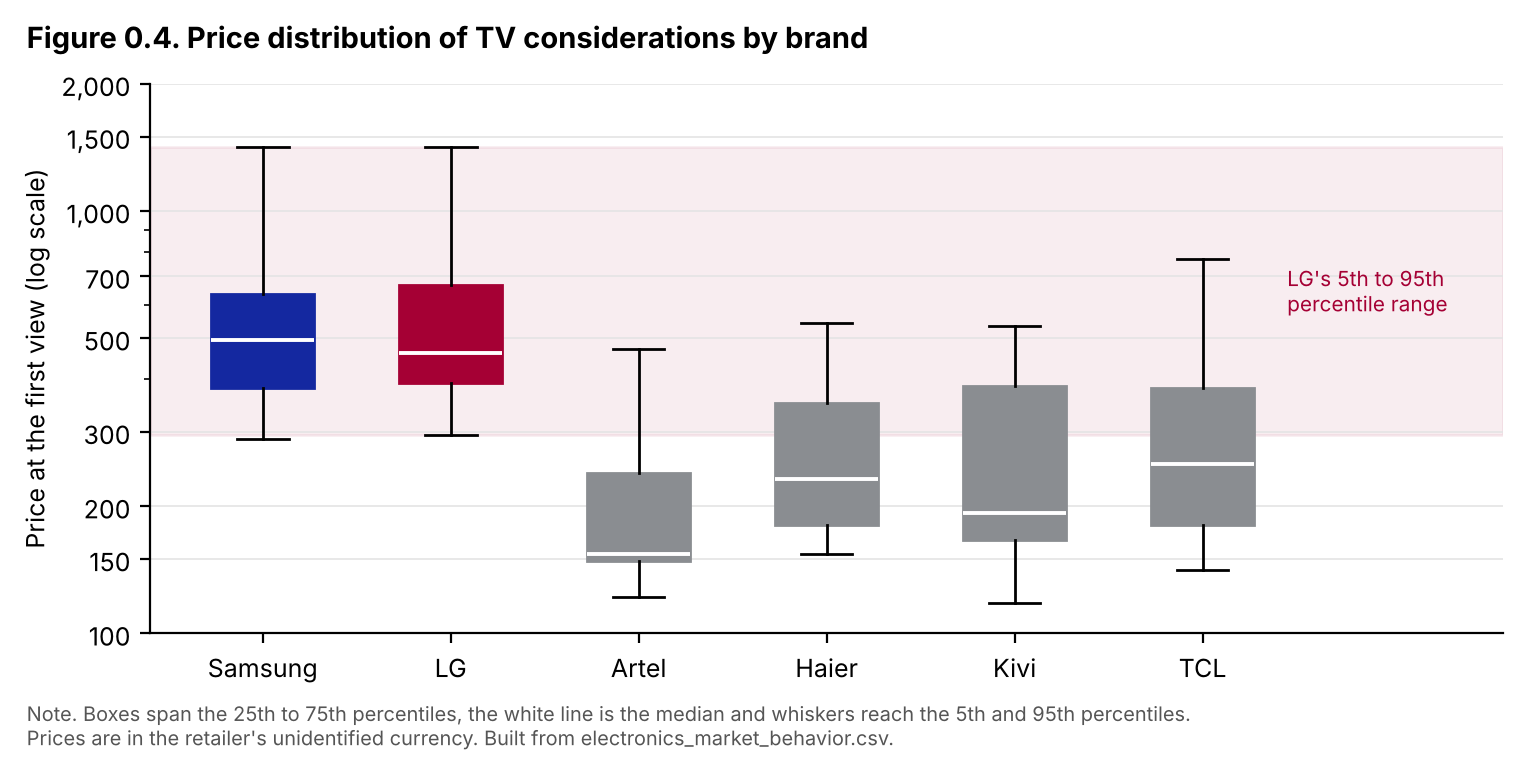

In [5]:
tv = cons[cons['product_category'] == 'tv']
NAMES = {'lg': 'LG', 'samsung': 'Samsung', 'artel': 'Artel', 'haier': 'Haier', 'kivi': 'Kivi', 'tcl': 'TCL'}
BRANDS = tv['brand'].value_counts().index.tolist()
b = pd.DataFrame({br: dict(zip(['rate', 'lo', 'hi'], mean_ci(d['purchased'], d['user_id'], d['product_id'])))
                  for br, d in tv.groupby('brand')}).T.loc[BRANDS]
b['share_cons'] = 100 * tv['brand'].value_counts()[BRANDS] / len(tv)
b['share_buys'] = 100 * tv.groupby('brand')['purchased'].sum()[BRANDS] / tv['purchased'].sum()

fig, ax = plt.subplots(figsize=(7.5, 3.6), layout='constrained')
y = np.arange(len(BRANDS))
ax.barh(y - 0.19, b['share_cons'], 0.38, color='#C9CDD3', label='Share of TV considerations')
ax.barh(y + 0.19, b['share_buys'], 0.38, color='#2F3542', label='Share of purchased TV considerations')
for i, br in enumerate(BRANDS):
    ax.text(b.loc[br, 'share_cons'] + 0.5, i - 0.19, f"{b.loc[br, 'share_cons']:.1f}%", va='center', fontsize=7.5)
    ax.text(b.loc[br, 'share_buys'] + 0.5, i + 0.19, f"{b.loc[br, 'share_buys']:.1f}%", va='center', fontsize=7.5)
ax.set_yticks(y, [NAMES[x] for x in BRANDS])
for lab in ax.get_yticklabels():
    if lab.get_text() == 'LG':
        lab.set_color(COLORS['lg']); lab.set_fontweight('bold')
ax.invert_yaxis()
ax.xaxis.set_major_formatter(pct)
ax.set_xlabel('Share of all TV considerations, or of all purchased TV considerations')
ax.set_xlim(0, b[['share_cons', 'share_buys']].max().max() * 1.15)
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
save_figure(fig, '0.2', 'Share of TV considerations and of purchased TV considerations by brand',
            "Each brand's share of all TV considerations is shown next to its share of all purchased TV considerations.",
            [F_BEH])

order = b.sort_values('rate').index.tolist()
fig, ax = plt.subplots(figsize=(7.5, 3.2), layout='constrained')
for i, br in enumerate(order):
    r = b.loc[br]
    ax.errorbar(r['rate'], i, xerr=[[r['rate'] - r['lo']], [r['hi'] - r['rate']]], fmt='o', color=COLORS.get(br, GREY),
                ms=6, capsize=3, elinewidth=1.2)
    ax.text(r['hi'] + 0.05, i, f"{r['rate']:.2f}%", va='center', fontsize=7.5)
overall = 100 * tv['purchased'].mean()
ax.axvline(overall, color='#999999', ls='--', lw=0.8)
ax.text(overall, len(order) - 0.45, f'All TV considerations {overall:.2f}%', fontsize=7.5, color='#666666', ha='center')
ax.set_yticks(range(len(order)), [NAMES[x] for x in order])
ax.xaxis.set_major_formatter(pct)
ax.set_xlabel('Conversion (share of considerations bought in the same session)')
ax.set_ylim(-0.6, len(order) - 0.2)
ax.grid(axis='y', visible=False)
save_figure(fig, '0.3', 'Conversion by TV brand', 'LG in red, Samsung in blue and the other four brands in grey. Bars are '
            '95% intervals.', [F_BEH])

price_rows = []
for c, d in cons.groupby('product_category'):
    lg_p = d.loc[d['brand'] == 'lg', 'price']
    l25, l50, l75 = lg_p.quantile([.25, .5, .75])
    l05, l95 = lg_p.quantile([.05, .95])
    for br, p in d.groupby('brand')['price']:
        q25, q50, q75 = p.quantile([.25, .5, .75])
        price_rows.append({'Category': CATEGORIES[c], 'Brand': BRAND_NAMES.get(br, br.capitalize()), 'is_lg': br == 'lg',
                           'Median price': q50,
                           "Distance from LG's median (%)": np.nan if br == 'lg' else 100 * abs(q50 / l50 - 1),
                           'Central-range overlap with LG': np.nan if br == 'lg' else max(0.0, min(q75, l75) - max(q25, l25)),
                           "Considerations inside LG's 5th to 95th percentile range (%)": 100 * p.between(l05, l95).mean()})
t05 = pd.DataFrame(price_rows)
t05['Category'] = pd.Categorical(t05['Category'], list(cat.index))
t05 = (t05.sort_values(['Category', 'is_lg', "Distance from LG's median (%)"], ascending=[True, False, True])
       .drop(columns='is_lg').set_index(['Category', 'Brand']))
save_table('0.5', 'Price at the first view of each brand against LG, by product category', t05,
           "Prices are in the retailer's unidentified currency and weight each consideration equally. Within each category "
           'LG comes first, followed by its competitors from the closest median price to the farthest.', [F_BEH])

lo, hi = tv.loc[tv['brand'] == 'lg', 'price'].quantile([.05, .95])
fig, ax = plt.subplots(figsize=(7.5, 3.4), layout='constrained')
bp = ax.boxplot([tv.loc[tv['brand'] == br, 'price'] for br in BRANDS], whis=(5, 95), showfliers=False, patch_artist=True,
                widths=0.55, medianprops={'color': 'white', 'lw': 1.4})
for patch, br in zip(bp['boxes'], BRANDS):
    patch.set_facecolor(COLORS.get(br, GREY)); patch.set_edgecolor(COLORS.get(br, GREY))
ax.axhspan(lo, hi, color=COLORS['lg'], alpha=0.07, zorder=0)
ax.text(len(BRANDS) + 0.45, np.sqrt(lo * hi), "LG's 5th to 95th\npercentile range", fontsize=7.5, color=COLORS['lg'],
        va='center')
ax.set_yscale('log')
ax.set_yticks([100, 150, 200, 300, 500, 700, 1000, 1500, 2000])
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xticks(range(1, len(BRANDS) + 1), [NAMES[x] for x in BRANDS])
ax.set_xlim(0.4, len(BRANDS) + 1.6)
ax.set_ylabel('Price at the first view (log scale)')
ax.grid(axis='x', visible=False)
save_figure(fig, '0.4', 'Price distribution of TV considerations by brand',
            'Boxes span the 25th to 75th percentiles, the white line is the median and whiskers reach the 5th and 95th '
            "percentiles. Prices are in the retailer's unidentified currency.", [F_BEH])

Samsung is the TV competitor whose prices are closest to LG's. It has the smallest distance from LG's median price and is the only TV competitor whose central price range overlaps LG's. It also has the largest share of TV considerations and the broadest range of competing models, while Artel, Haier, Kivi and TCL sell mostly cheaper sets. Samsung is also the closest-priced competitor in four of the other five categories (Tefal is closer in vacuum cleaners), so the choice does not rest on TVs alone. The data hold no product specifications, so the benchmark matches price levels only.

The other four TV brands stay in the data, because they are part of the paths that lead shoppers to LG and Samsung models. A benchmark that pooled all rivals was not used, because it would change whenever the rivals' prices or product mix changed.

## 5. Research directions considered

The exploration tried several questions before settling on the one in Section 1. The table records each direction, what it offered and what the project keeps from it.

| Direction | What it offered | Why it is not the main question | What the project keeps |
| --- | --- | --- | --- |
| Gaps at each funnel stage (view to cart, cart to purchase), with separate logit models | Shows where in the purchase path LG falls behind | The two stages have different denominators, a cart already selects shoppers, and the stages leave out reach | The funnel in Figure 2.2 |
| Conversion adjusted only for price and month | One outcome and a simple model | It leaves out the shopper's browsing and the reach part of the shortfall | Price and week as controls in the models of `03_models.ipynb` |
| Conversion after another brand was opened earlier | Uses only information available before the model is opened | An adjusted difference does not identify what causes it | The supporting question and the browsing controls |
| Shopper types over the whole two months (one brand only, or both) | Shows that the two brands attract different browsing profiles | The types use behaviour after the consideration, and user histories are incomplete | Browsing within the session before the first view |
| Washing machines | A large sample with slightly more LG purchases than TVs | A different product and decision, with no reason to prefer it over TVs | Table 0.4 |
| Other categories, or all competitors pooled | Tests whether the choice of TVs and Samsung is arbitrary | Support, prices and assortment differ across categories, and a pooled benchmark changes with the rivals' mix | Tables 0.4 and 0.5 and Figure 0.1 |
| Satisfaction and review topics | Ratings and text for LG and Samsung appliances | Different products, users and years, no TVs and no link to purchases | Tables 0.2 and 0.3 |
| Segmentation of shoppers (RFM, k-means) | Could group shoppers if a targeting decision required it | The file has no demographics or complete histories, and clusters do not explain the gap | The observed browsing variables |
| Price elasticity or optimal discounts | A direct economic decision | No price experiment, costs or margins, and listed prices change with the product mix | Price as a control, and the within-model price changes in `03_models.ipynb` |

## 6. Limits that apply to the whole project

- The data cover one retailer over two months, in a sample of sessions. Purchases elsewhere, in unsampled sessions or after 30 November are not observed.
- The data contain no product specifications, stock, placement, advertising, costs or margins, and prices change with the product mix.
- Every result describes an association. None of them identifies a faulty page, a causal effect of the audience mix, an optimal discount or a budget allocation.
- A difference that is not statistically significant does not show that two groups convert equally.

In [6]:
pd.DataFrame(EXHIBITS).to_csv(OUT / 'exhibit_index.csv', index=False)
print(f"Saved {len(EXHIBITS)} exhibits to {OUT}")

Saved 9 exhibits to results/scope
